In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mehradaria/leukemia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'leukemia' dataset.
Path to dataset files: /kaggle/input/leukemia


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255,validation_split=0.2)

In [ ]:
import os
train_generator = train_datagen.flow_from_directory(os.path.join(path,"Original"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

Found 2607 images belonging to 4 classes.


In [ ]:
import os
val_generator = train_datagen.flow_from_directory(os.path.join(path,"Original"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Found 649 images belonging to 4 classes.


In [ ]:
class_indices = train_generator.class_indices
class_names = list(class_indices.keys())
print("Class indices:", class_indices)
print("Class names:", class_names)


Class indices: {'Benign': 0, 'Early': 1, 'Pre': 2, 'Pro': 3}
Class names: ['Benign', 'Early', 'Pre', 'Pro']


In [ ]:
model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu',
input_shape=(IMG_SIZE,IMG_SIZE,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(4, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy',
metrics=['accuracy'])

In [ ]:
model.fit(train_generator,validation_data=val_generator,epochs=10)

Epoch 1/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 31s 286ms/step - accuracy: 0.6444 - loss: 0.9106 - val_accuracy: 0.6564 - val_loss: 1.0202
Epoch 2/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 89ms/step - accuracy: 0.8412 - loss: 0.3867 - val_accuracy: 0.6595 - val_loss: 0.9182
Epoch 3/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.8991 - loss: 0.2539 - val_accuracy: 0.7319 - val_loss: 0.9090
Epoch 4/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.9191 - loss: 0.2026 - val_accuracy: 0.6425 - val_loss: 1.1628
Epoch 5/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - accuracy: 0.9348 - loss: 0.1608 - val_accuracy: 0.6872 - val_loss: 1.7324
Epoch 6/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 8s 93ms/step - accuracy: 0.9440 - loss: 0.1473 - val_accuracy: 0.7257 - val_loss: 0.9796
Epoch 7/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.9628 - loss: 0.1009 - val_accuracy: 0.7689 - val_loss: 0.8262
Epoch 8/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.9689 - loss: 0.0902 - val_accuracy: 0.7982 -

In [ ]:
model.save('leukemia.h5')


In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
model = load_model('leukemia.h5')
print("Model Loaded")

Model Loaded


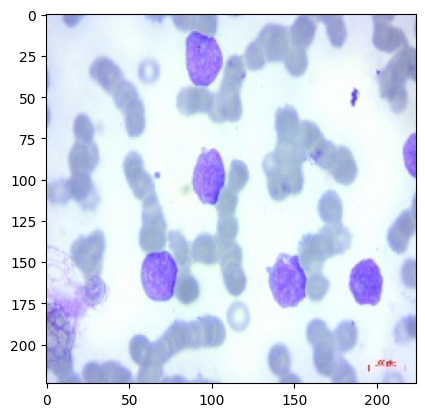

In [ ]:
from matplotlib import pyplot as plt
test_image_path = r"/content/drive/MyDrive/Leukemia1.jpg"
img = image.load_img(test_image_path, target_size=(224, 224))
plt.imshow(img)
plt.axis()
plt.show()

In [ ]:
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255.

In [ ]:
prediction = model.predict(img_array)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 870ms/step
[[8.3945785e-03 9.2050487e-01 7.1100526e-02 2.1917520e-12]]


In [ ]:
prediction =model.predict(img_array)
ind =np.argmax(prediction[0])
print(class_names[ind])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Early
